In [1]:
#
#
#

import arslabrobotics as ar

import numpy as np
import scipy

# continuous time matrices
A = np.array( [ [-0.9, 0],
                [1, 0] ])
B = np.array([ [1], [0] ])

delta_t = 0.1  # 100ms

# discrete time matrices
A = np.eye(2) + A * delta_t
B = B * delta_t

print("State Matrix:\n", A)
print("Input Matrix:\n", B)


State Matrix:
 [[0.91 0.  ]
 [0.1  1.  ]]
Input Matrix:
 [[0.1]
 [0. ]]


In [6]:

Q = np.eye( 2, dtype=np.float32) * 1
R = np.eye( 1, dtype=np.float32) * 10

P = scipy.linalg.solve_discrete_are(A, B, Q, R)
K = np.linalg.inv(R + B.T @ P @ B) @ B.T @ P @ A

print("Optimal Gain:", K)


Optimal Gain: [[0.34064811 0.31080244]]


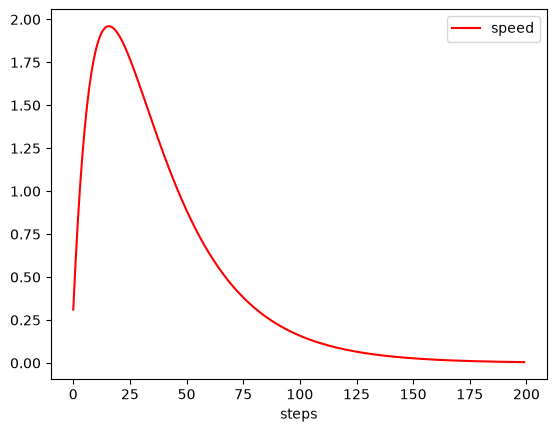

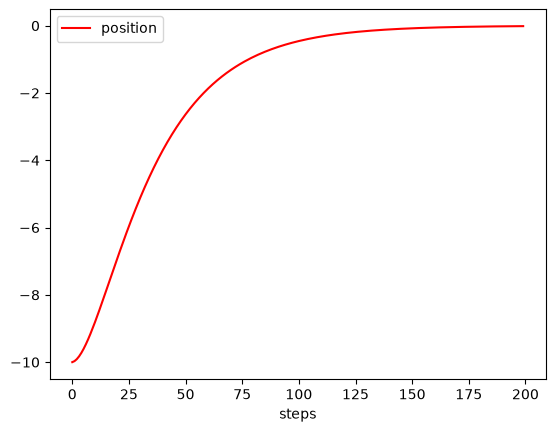

In [7]:

# starting speed = 0
# starting position = -10
x = np.array([ 0., -10.])

dps = ar.data.DataPlotter()
dps.set_x("steps")
dps.add_y("speed", "speed")

dpp = ar.data.DataPlotter()
dpp.set_x("steps")
dpp.add_y("pos", "position")

for t in range(0,200):
    u = - K @ x
    x = A @ x + B @ u
    dps.append_x(t)
    dps.append_y("speed", x[0])
    dpp.append_x(t)
    dpp.append_y("pos", x[1])

dps.plot()
dpp.plot()
